#Download data and unzip folder

In [1]:
#!/bin/bash
!kaggle datasets download justsahil/movielens-32m
!unzip movielens-32m.zip

path = "/content/ml-32m"

Dataset URL: https://www.kaggle.com/datasets/justsahil/movielens-32m
License(s): apache-2.0
100% 231M/231M [00:01<00:00, 154MB/s]

Archive:  movielens-32m.zip
  inflating: ml-32m/README.txt       
  inflating: ml-32m/checksums.txt    
  inflating: ml-32m/links.csv        
  inflating: ml-32m/movies.csv       
  inflating: ml-32m/ratings.csv      
  inflating: ml-32m/tags.csv         


In [ ]:
import csv
import matplotlib.pyplot as plt
from collections import Counter
import random

class RatingMap:

  def __init__(self,path):

    self.number_of_users = 0
    self.number_of_items = 0

    self.user_to_index = {}
    self.index_to_user = []
    self.item_to_index = {}
    self.index_to_item = []

    self.data_by_user = []
    self.data_by_item = []

    self.user_train = []
    self.user_test = []
    self.item_train = []
    self.item_test = []

    self.split_cutoff = 0.2

    i = 0
    data_count = 100000
    with open(path+"/ratings.csv") as csv_file:

        self.rows = csv.reader(csv_file, delimiter=',')
        next(self.rows)
        for row in self.rows:
          # counter to limit data
          i+=1
          if i > data_count:
            break


          # extracting data from a single row
          user_id =  row[0]
          item_id = row[1]
          rating =   float(row[2])

          # mapping dictionaries for new users and new items
          if user_id not in self.user_to_index:
            self.index_to_user.append(user_id)
            self.data_by_user.append([])
            self.user_train.append([])
            self.user_test.append([])
            self.user_to_index[user_id] = len(self.index_to_user)-1

          if item_id not in self.item_to_index:
            self.index_to_item.append(item_id)
            self.data_by_item.append([])
            self.item_train.append([])
            self.item_test.append([])
            self.item_to_index[item_id] = len(self.index_to_item)-1


          # storing in data lists
          self.data_by_user[self.user_to_index[user_id]].append((self.item_to_index[item_id], rating))
          self.data_by_item[self.item_to_index[item_id]].append((self.user_to_index[user_id], rating))

          # cutoff for train-test split
          if random.random() > self.split_cutoff:
            self.user_train[self.user_to_index[user_id]].append((self.item_to_index[item_id], rating))
            self.item_train[self.item_to_index[item_id]].append((self.user_to_index[user_id], rating))
          else:
            self.user_test[self.user_to_index[user_id]].append((self.item_to_index[item_id], rating))
            self.item_test[self.item_to_index[item_id]].append((self.user_to_index[user_id], rating))

        # record number of users and items
        self.number_of_users = len(self.user_to_index)
        self.number_of_items = len(self.item_to_index)


  def get_user_ratings(self,user_id):
    user_ratings = self.data_by_user[self.user_to_index[user_id]]
    return user_ratings

  def get_item_ratings(self,item_id):
    item_ratings = self.data_by_item[self.item_to_index[item_id]]
    return item_ratings

  def get_rating_by_user_and_item(self, user_index, item_index):
    for (n, r) in self.data_by_user[user_index]:
      if n == self.index_to_item[item_index]:
        return r

  def train_test_split(self):
    return self.user_train, self.user_test, self.item_train, self.item_test

  def plot_powerlaw(self):
    user_deg = Counter(len(r) for r in self.data_by_user)
    item_deg = Counter(len(r) for r in self.data_by_item)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    for ax in (ax1, ax2):
        ax.plot(list(item_deg.keys()), list(item_deg.values()),
                marker=".", linestyle="none", color="tab:orange", label="Movies")
        ax.plot(list(user_deg.keys()), list(user_deg.values()),
                marker=".", linestyle="none", color="tab:blue", label="Users")
        ax.set_xlabel("Degree")
        ax.set_ylabel("Frequency")
        ax.grid(True)
        ax.legend()

    ax1.set_title("Normal scale")
    ax2.set_title("Log-log scale")
    ax2.set_xscale("log")
    ax2.set_yscale("log")

    plt.tight_layout()
    plt.show()



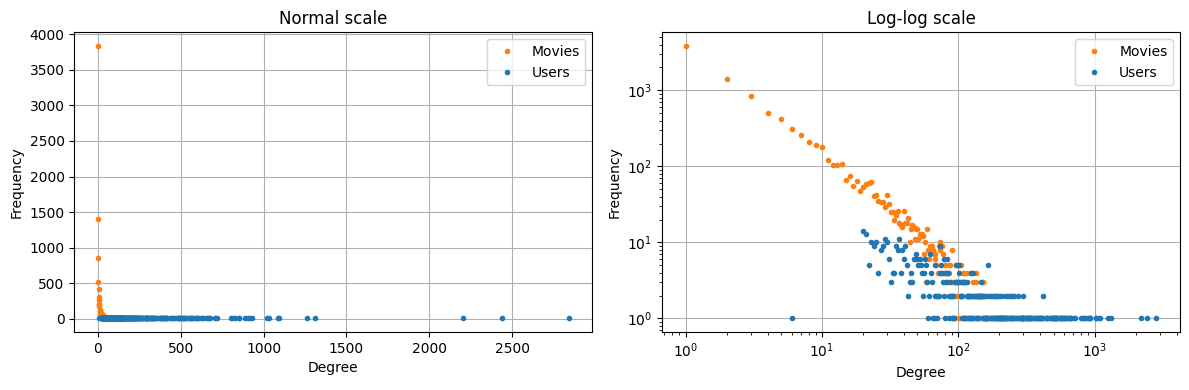

In [ ]:
rating = RatingMap(path)
rating.plot_powerlaw()

# Practical 2:

In [ ]:
def rmse_calculation(users_set, users_biases, items_biases):
  mean = 0.0
  number_of_ratings = 0

  for user in range(len(users_set)):
    for (n, r) in users_set[user]:
      mean += (r - items_biases[n] - users_biases[user])**2
      number_of_ratings += 1

  mean /= number_of_ratings
  loss = np.sqrt(mean)
  return loss

In [ ]:
import numpy as np

num_of_epochs = 10
lamb =  0.01
gamma = 0.005
tau = 0.01

training_loss_logs = []
training_rmse_logs = []
test_rmse_logs = []
users_train, users_test, items_train, items_test = rating.train_test_split()

number_of_users = rating.number_of_users
number_of_items = rating.number_of_items

# intialize biases
users_biases = np.zeros((number_of_users))
items_biases = np.zeros((number_of_items))


for i in range(num_of_epochs):
# users bias
  for user_index in range(number_of_users):
    bias = 0
    item_counter = 0
    if len(users_train[user_index]) == 0:
      continue
    for (n, r) in users_train[user_index]:
      bias +=  (r - items_biases[n])
      item_counter += 1

    bias = (lamb * bias) / (lamb * item_counter + gamma)
    users_biases[user_index] = bias


# items bias
  for item_index in range(number_of_items):
      bias = 0
      user_counter = 0
      loss = 0
      if len(items_train[item_index]) == 0:
        continue
      for (m, r) in items_train[item_index]:
        bias += (r - users_biases[m])
        user_counter += 1

      bias = (lamb * bias)  / (lamb * user_counter + gamma)
      items_biases[item_index] = bias

  for item_index in range(number_of_items):
    for (m, r) in items_train[item_index]:
      loss += (lamb/2) * (r - users_biases[m] - items_biases[item_index])**2



  # training loss calculation
  loss += (gamma/2)*(np.square(users_biases).sum() + np.square(items_biases).sum())
  training_loss_logs.append(loss)




# training loss calculation
  training_rmse_logs.append(rmse_calculation(users_train, users_biases, items_biases).item())

# test loss calculation
  test_rmse_logs.append(rmse_calculation(users_test, users_biases, items_biases).item())




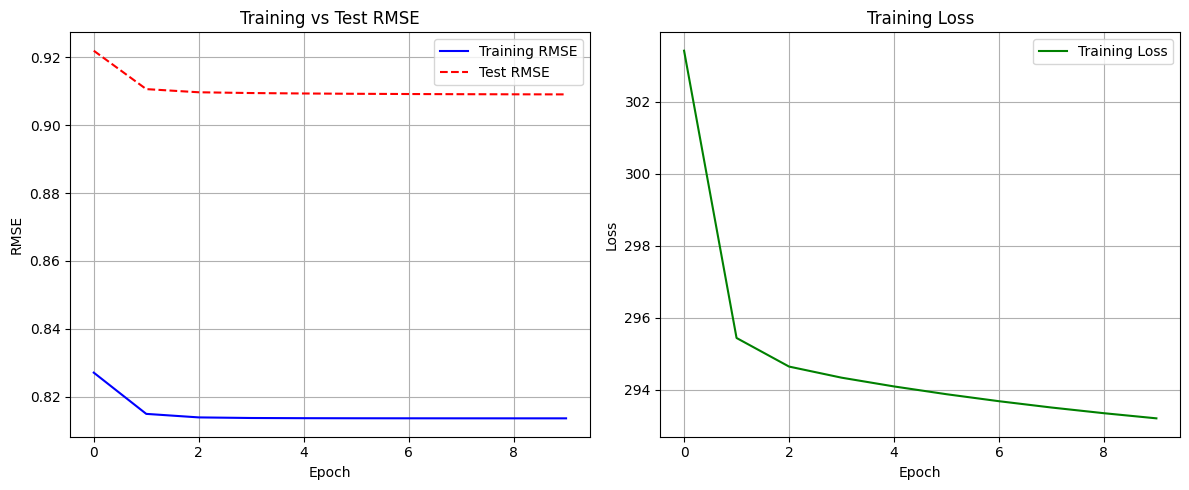

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Training vs Test RMSE
ax1.plot(training_rmse_logs, color='blue', linestyle='-', label='Training RMSE')
ax1.plot(test_rmse_logs, color='red', linestyle='--', label='Test RMSE')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('RMSE')
ax1.set_title('Training vs Test RMSE')
ax1.legend()
ax1.grid(True)

# Plot 2: Training Loss
ax2.plot(training_loss_logs, color='green', linestyle='-', label='Training Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.set_title('Training Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

#Practical 3

In [ ]:
def rmse_calculation(users_set, users_biases, items_biases):
  mean = 0
  number_of_ratings = 0

  for user in range(len(users_set)):
    for (n, r) in users_set[user]:
      mean = mean + (r - (users_embeddings[user][:,None].T @ items_embeddings[n][:,None] + items_biases[n] + users_biases[user]))**2
      number_of_ratings += 1

  mean /= number_of_ratings
  loss = np.sqrt(mean)
  return loss

In [ ]:
import numpy as np

num_of_epochs = 100
lamb =  0.01
gamma = 0.005
tau = 0.01

training_loss_logs = []
training_rmse_logs = []
test_rmse_logs = []
users_train, users_test, items_train, items_test = rating.train_test_split()

number_of_users = rating.number_of_users
number_of_items = rating.number_of_items

# intialize biases
users_biases = np.zeros((number_of_users))
items_biases = np.zeros((number_of_items))

# initialize embeddings
k = 32
rng = np.random.default_rng()
users_embeddings = rng.normal(loc=0, scale=np.sqrt(k), size=(number_of_users,k))
items_embeddings = rng.normal(loc=0, scale=np.sqrt(k), size=(number_of_items,k))

for i in range(num_of_epochs):
  loss = 0


# users bias
  for user_index in range(number_of_users):
    bias = 0
    item_counter = 0

    for (n, r) in users_train[user_index]:
      bias += lamb * (r - users_embeddings[user_index][:,None].T @ items_embeddings[n][:,None] - items_biases[n])
      item_counter += 1

    bias = bias / (lamb * item_counter + gamma)
    users_biases[user_index] = bias

# users embeddings
  for user_index in range(number_of_users):
    numerator = 0
    denumerator = 0
    number_of_ratings = 0

    for (n, r) in users_train[user_index]:
      number_of_ratings += 1
      items_vecor = items_embeddings[n][:,None]
      numerator += items_vecor *  (r - items_biases[n] - users_biases[user_index])
      denumerator += items_vecor @ items_vecor.T

    numerator *= lamb
    denumerator = denumerator * lamb + gamma * np.identity(k)
    if number_of_ratings != 0:
      users_embeddings[user_index] = np.squeeze(np.linalg.inv(denumerator) @ numerator)

# items bias
  for item_index in range(number_of_items):
      bias = 0
      user_counter = 0

      for (m, r) in items_train[item_index]:
        bias += lamb * (r - items_embeddings[item_index][:,None].T @ users_embeddings[m][:,None] - users_biases[m])
        user_counter += 1

      bias = bias / (lamb * user_counter + gamma)
      items_biases[item_index] = bias
# items embeddings
  for item_index in range(number_of_items):
    numerator = 0
    denumerator = 0
    number_of_ratings = 0


    for (m, r) in items_train[item_index]:
      number_of_ratings += 1
      user_vector = users_embeddings[m][:,None]
      numerator += user_vector *  (r - items_biases[item_index] - users_biases[m])
      denumerator += user_vector @ user_vector.T

    numerator *= lamb
    denumerator = denumerator * lamb + tau * np.identity(k)
    if number_of_ratings != 0:
      items_embeddings[item_index] = np.squeeze(np.linalg.inv(denumerator) @ numerator)

  for item_index in range(number_of_items):
    for (m, r) in items_train[item_index]:
      loss += (lamb/2) * (r - users_embeddings[m][:,None].T @ items_embeddings[item_index][:,None] - users_biases[m] - items_biases[item_index])**2
    loss += (tau/2) * np.linalg.norm(items_embeddings[item_index])

  for user_index in range(number_of_users):
    loss += (tau/2) * np.linalg.norm(users_embeddings[user_index])


  # training loss calculation
  loss += (gamma/2)*(np.square(users_biases).sum() + np.square(items_biases).sum())
  training_loss_logs.append(loss.item())


# training loss calculation
  training_rmse_logs.append(rmse_calculation(users_train, users_biases, items_biases).item())
  test_rmse_logs.append(rmse_calculation(users_test, users_biases, items_biases).item())
# test loss calculation




/tmp/ipykernel_3080/1608463544.py:40: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  users_biases[user_index] = bias
/tmp/ipykernel_3080/1608463544.py:69: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  items_biases[item_index] = bias


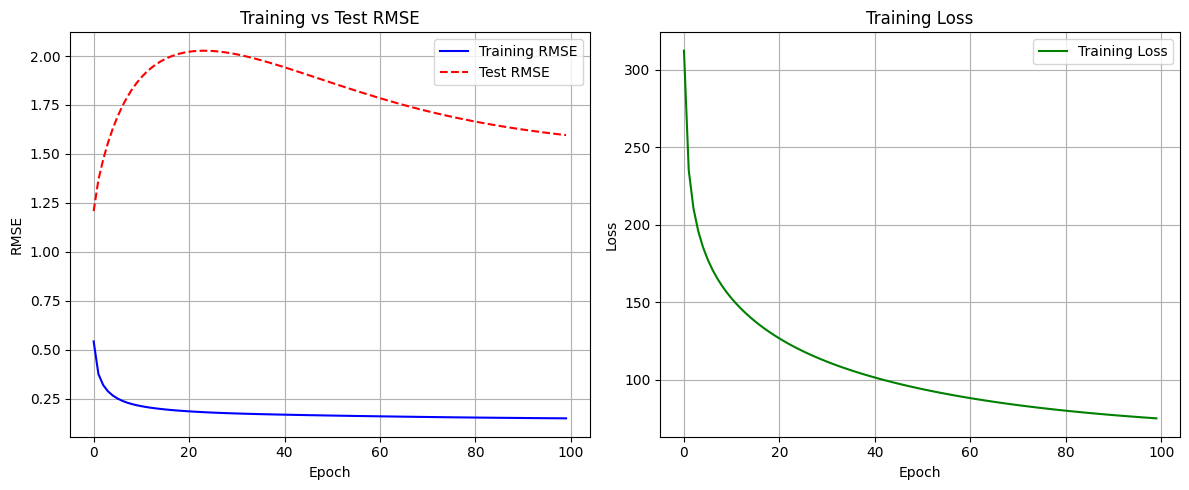

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Training vs Test RMSE
ax1.plot(training_rmse_logs, color='blue', linestyle='-', label='Training RMSE')
ax1.plot(test_rmse_logs, color='red', linestyle='--', label='Test RMSE')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('RMSE')
ax1.set_title('Training vs Test RMSE')
ax1.legend()
ax1.grid(True)

# Plot 2: Training Loss
ax2.plot(training_loss_logs, color='green0', linestyle='-', label='Training Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.set_title('Training Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

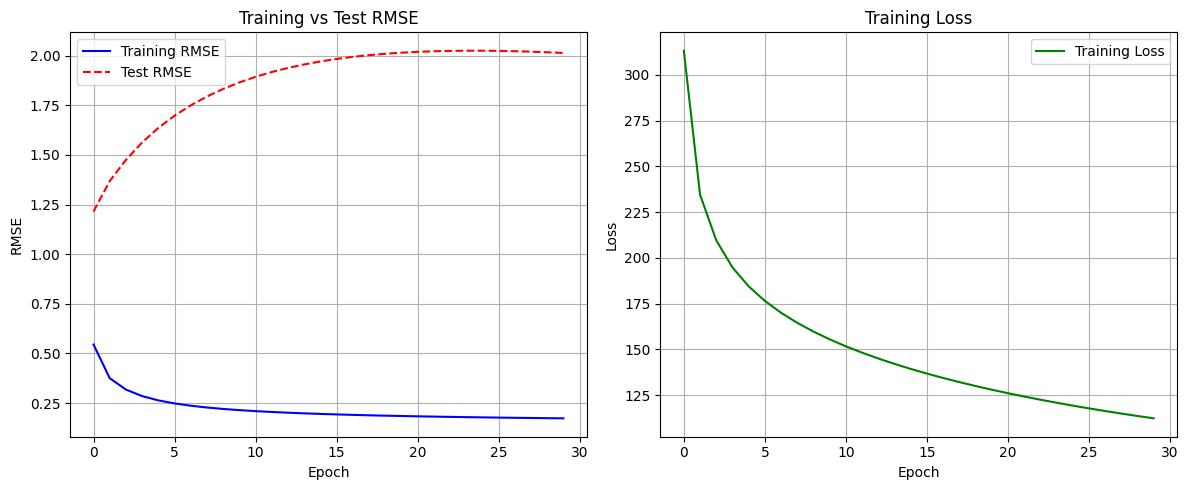

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Training vs Test RMSE
ax1.plot(training_rmse_logs, color='blue', linestyle='-', label='Training RMSE')
ax1.plot(test_rmse_logs, color='red', linestyle='--', label='Test RMSE')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('RMSE')
ax1.set_title('Training vs Test RMSE')
ax1.legend()
ax1.grid(True)

# Plot 2: Training Loss
ax2.plot(training_loss_logs, color='green', linestyle='-', label='Training Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.set_title('Training Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

#Practical 4

1-run the training loop for the same rarting (toy story for example) like 4 or 5 times for the same tuple, so you can get a user vector and a user bias that is near to it.

2-calculate the score for each movie then sort them

3-do not forget that you are supposed to have items matrix and biases already stored in disk.

##Loading data with CSR



In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

class RatingMap:

  def __init__(self, path, chunk_size=2_000_000, data_count=None ):

    self.split_cutoff = 0.2

    # read the csv in chunks, straight into small typed arrays (no python objects per rating)
    users_chunks = []
    items_chunks = []
    ratings_chunks = []
    rows_loaded = 0

    for chunk in pd.read_csv(path+"/ratings.csv", names=["u", "i", "r"], header=0, usecols=[0, 1, 2],
                             dtype={"u": np.int32, "i": np.int32, "r": np.float32}, chunksize=chunk_size):
      # If a limit is specified, truncate the chunk to not exceed data_count total rows
      if data_count is not None:
        remaining = data_count - rows_loaded
        if remaining <= 0:
          break
        if len(chunk) > remaining:
          chunk = chunk.iloc[:remaining]

      users_chunks.append(chunk["u"].to_numpy())
      items_chunks.append(chunk["i"].to_numpy())
      ratings_chunks.append(chunk["r"].to_numpy())

      rows_loaded += len(chunk)
      if data_count is not None and rows_loaded >= data_count:
        break

    raw_users = np.concatenate(users_chunks)
    raw_items = np.concatenate(items_chunks)
    ratings = np.concatenate(ratings_chunks)
    del users_chunks, items_chunks, ratings_chunks

    # map raw ids to indices 0..n-1 with a lookup table (no dictionaries, no sorting)
    user_of_each_rating, self.index_to_user = self.map_ids(raw_users)
    item_of_each_rating, self.index_to_item = self.map_ids(raw_items)
    del raw_users, raw_items

    self.number_of_users = len(self.index_to_user)
    self.number_of_items = len(self.index_to_item)

    # degrees (for the power law plot), computed before the full arrays are dropped
    self.user_degrees = np.bincount(user_of_each_rating, minlength=self.number_of_users)
    self.item_degrees = np.bincount(item_of_each_rating, minlength=self.number_of_items)

    # train-test split on the flat arrays
    mask = np.random.default_rng().random(len(ratings), dtype=np.float32) > self.split_cutoff

    self.train_users = user_of_each_rating[mask]
    self.train_items = item_of_each_rating[mask]
    self.train_ratings = ratings[mask]

    self.test_users = user_of_each_rating[~mask]
    self.test_items = item_of_each_rating[~mask]
    self.test_ratings = ratings[~mask]
    del user_of_each_rating, item_of_each_rating, ratings, mask

    # ordering by users (train only)
    users_order = np.argsort(self.train_users, kind="stable")
    self.items_ordered_by_users = self.train_items[users_order]
    self.ratings_ordered_by_users = self.train_ratings[users_order]
    self.users_pointers = np.concatenate([[0], np.cumsum(self.user_train_counts())])
    del users_order

    # ordering by items (train only)
    items_order = np.argsort(self.train_items, kind="stable")
    self.users_ordered_by_items = self.train_users[items_order]
    self.ratings_ordered_by_items = self.train_ratings[items_order]
    self.items_pointers = np.concatenate([[0], np.cumsum(self.item_train_counts())])
    del items_order

  @staticmethod
  def map_ids(raw_ids):
    present = np.zeros(raw_ids.max() + 1, dtype=bool)
    present[raw_ids] = True
    index_to_id = np.flatnonzero(present)
    lookup = (np.cumsum(present) - 1).astype(np.int32)
    return lookup[raw_ids], index_to_id

  def user_train_counts(self):
    return np.bincount(self.train_users, minlength=self.number_of_users)

  def item_train_counts(self):
    return np.bincount(self.train_items, minlength=self.number_of_items)

  def plot_powerlaw(self):
    user_deg = Counter(self.user_degrees.tolist())
    item_deg = Counter(self.item_degrees.tolist())

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    for ax in (ax1, ax2):
        ax.plot(list(item_deg.keys()), list(item_deg.values()),
                marker=".", linestyle="none", color="tab:orange", label="Movies")
        ax.plot(list(user_deg.keys()), list(user_deg.values()),
                marker=".", linestyle="none", color="tab:blue", label="Users")
        ax.set_xlabel("Degree")
        ax.set_ylabel("Frequency")
        ax.grid(True)
        ax.legend()

    ax1.set_title("Normal scale")
    ax2.set_title("Log-log scale")
    ax2.set_xscale("log")
    ax2.set_yscale("log")

    plt.tight_layout()
    plt.show()

In [24]:
ratings = RatingMap(path)

In [25]:
def predict(users, items, users_embeddings, items_embeddings, users_biases, items_biases):
  return (np.einsum("nk,nk->n", users_embeddings[users], items_embeddings[items])
          + users_biases[users] + items_biases[items])


def rmse_calculation(users, items, ratings, users_embeddings, items_embeddings, users_biases, items_biases):
  predictions = predict(users, items, users_embeddings, items_embeddings, users_biases, items_biases)
  return np.sqrt(np.mean((ratings - predictions) ** 2))

##CSR without Numba

In [39]:
import numpy as np

num_of_epochs = 10
lamb =  0.01
gamma = 0.005
tau = 0.01

training_loss_logs = []
training_rmse_logs = []
test_rmse_logs = []

train_users, train_items, train_ratings = ratings.train_users, ratings.train_items, ratings.train_ratings
test_users,  test_items,  test_ratings  = ratings.test_users,  ratings.test_items,  ratings.test_ratings

number_of_users = ratings.number_of_users
number_of_items = ratings.number_of_items

# intialize biases
users_biases = np.zeros((number_of_users))
items_biases = np.zeros((number_of_items))

# initialize embeddings
k = 32
rng = np.random.default_rng()
users_embeddings = rng.normal(loc=0, scale=np.sqrt(k), size=(number_of_users,k))
items_embeddings = rng.normal(loc=0, scale=np.sqrt(k), size=(number_of_items,k))

ratings_by_users = ratings.ratings_ordered_by_users
users_pointers = ratings.users_pointers
items_by_user = ratings.items_ordered_by_users

ratings_by_items = ratings.ratings_ordered_by_items
items_pointers = ratings.items_pointers
users_by_items = ratings.users_ordered_by_items

# prediction and rmse helpers (chunked to keep memory low)
def predict(users, items, users_embeddings, items_embeddings, users_biases, items_biases, chunk=1_000_000):
  predictions = np.empty(len(users))
  for start in range(0, len(users), chunk):
    u = users[start:start+chunk]
    it = items[start:start+chunk]
    predictions[start:start+chunk] = (np.einsum("nk,nk->n", users_embeddings[u], items_embeddings[it])
                                      + users_biases[u] + items_biases[it])
  return predictions

def rmse_calculation(users, items, ratings_, users_embeddings, items_embeddings, users_biases, items_biases):
  predictions = predict(users, items, users_embeddings, items_embeddings, users_biases, items_biases)
  return np.sqrt(np.mean((ratings_ - predictions) ** 2))

for i in range(num_of_epochs):

# users loop
  for user in range(ratings.number_of_users):
    s, e = users_pointers[user], users_pointers[user + 1]
    items = items_by_user[s:e]
    Vu = items_embeddings[items]                                  # (n_u, k)
    number_of_ratings = e - s

    # bias, using the current embedding
    resid = ratings_by_users[s:e] - Vu @ users_embeddings[user] - items_biases[items]
    users_biases[user] = lamb * resid.sum() / (lamb * number_of_ratings + gamma)

    # embedding, using the new bias
    y = ratings_by_users[s:e] - items_biases[items] - users_biases[user]
    A = lamb * (Vu.T @ Vu) + gamma * np.identity(k)
    users_embeddings[user] = np.linalg.solve(A, lamb * (Vu.T @ y))
# items loop
  for item in range(number_of_items):
    s, e = items_pointers[item], items_pointers[item + 1]
    users = users_by_items[s:e]
    Uv = users_embeddings[users]                                  # (n_i, k)
    number_of_ratings = e - s

    # bias, using the current embedding
    resid = ratings_by_items[s:e] - Uv @ items_embeddings[item] - users_biases[users]
    items_biases[item] = lamb * resid.sum() / (lamb * number_of_ratings + gamma)

    # embedding, using the new bias
    y = ratings_by_items[s:e] - users_biases[users] - items_biases[item]
    A = lamb * (Uv.T @ Uv) + tau * np.identity(k)
    items_embeddings[item] = np.linalg.solve(A, lamb * (Uv.T @ y))

  # training loss calculation
  errors = train_ratings - predict(train_users, train_items, users_embeddings, items_embeddings, users_biases, items_biases)

  loss = ((lamb / 2) * np.sum(errors ** 2)
          + (gamma / 2) * np.sum(users_embeddings ** 2)
          + (tau / 2) * np.sum(items_embeddings ** 2)
          + (gamma / 2) * (np.sum(users_biases ** 2) + np.sum(items_biases ** 2)))

  training_loss_logs.append(loss)
  training_rmse_logs.append(np.sqrt(np.mean(errors ** 2)))
  test_rmse_logs.append(rmse_calculation(test_users, test_items, test_ratings,
                                         users_embeddings, items_embeddings, users_biases, items_biases))
  print(i, training_loss_logs[-1], training_rmse_logs[-1], test_rmse_logs[-1])

0 10470296.272490041 8.832031485927734 25.18842765680624
1 868505.4248365978 2.0504101822789176 10.450078191856724
2 452505.7574589678 1.09956199303771 5.661415311861335
3 372195.3224767151 0.8495674676170697 3.541621711864172
4 340343.8890112464 0.7604773048551262 2.4796736672440605
5 321162.4966291356 0.7195168592953219 1.921407032058713
6 306329.5191682336 0.6944183816087963 1.6140609588435337
7 293578.54917806666 0.6762130491838463 1.4338504073925569
8 282168.9362112949 0.6621483081498024 1.3208395194753504
9 271756.3235402992 0.6509723789753965 1.2451420099305899


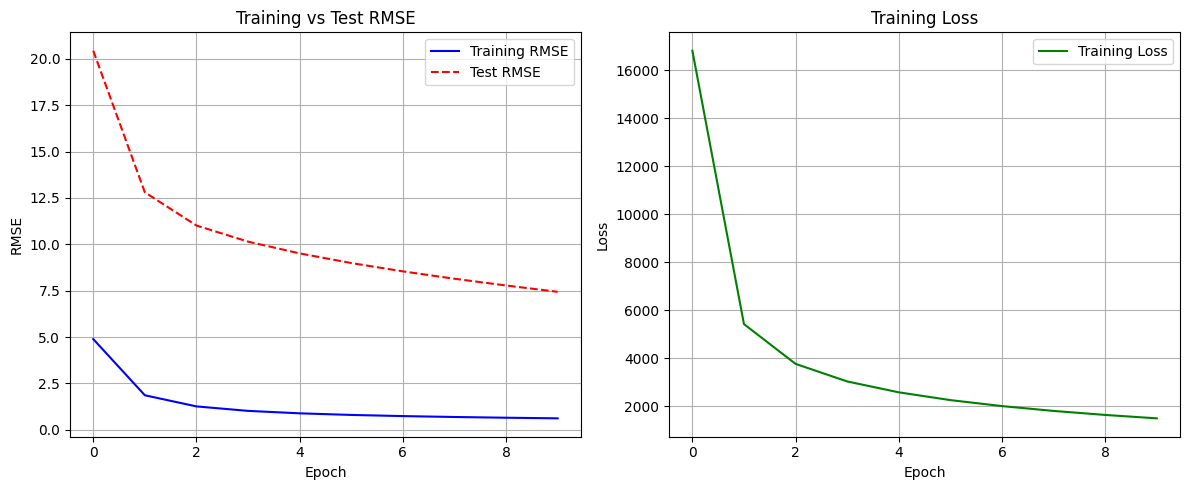

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Training vs Test RMSE
ax1.plot(training_rmse_logs, color='blue', linestyle='-', label='Training RMSE')
ax1.plot(test_rmse_logs, color='red', linestyle='--', label='Test RMSE')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('RMSE')
ax1.set_title('Training vs Test RMSE')
ax1.legend()
ax1.grid(True)

# Plot 2: Training Loss
ax2.plot(training_loss_logs, color='green', linestyle='-', label='Training Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.set_title('Training Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

##Using Numba

In [26]:
import numba as nb

@nb.njit(parallel=True, fastmath=True)
def update_side(pointers, others, rates, other_emb, other_bias, emb, bias, lamb, gamma, reg):
  n = len(pointers) - 1
  k = emb.shape[1]
  for idx in nb.prange(n):
    s, e = pointers[idx], pointers[idx + 1]

    # bias, using the current embedding
    total = 0.0
    for p in range(s, e):
      o = others[p]
      pred = other_bias[o]
      for a in range(k):
        pred += other_emb[o, a] * emb[idx, a]
      total += rates[p] - pred
    bias[idx] = lamb * total / (lamb * (e - s) + gamma)

    # embedding, using the new bias: accumulate A = sum v v^T and b = sum v y
    A = np.zeros((k, k))
    b = np.zeros(k)
    for p in range(s, e):
      o = others[p]
      y = rates[p] - other_bias[o] - bias[idx]
      for a in range(k):
        v = other_emb[o, a]
        b[a] += v * y
        for c in range(a, k):                 # upper triangle only
          A[a, c] += v * other_emb[o, c]

    for a in range(k):
      for c in range(a):
        A[a, c] = A[c, a]                     # mirror to the lower triangle
      A[a, a] = lamb * A[a, a] + reg
      for c in range(a + 1, k):
        A[a, c] = lamb * A[a, c]
        A[c, a] = A[a, c]
    emb[idx] = np.linalg.solve(A, lamb * b)

In [27]:
import numpy as np

num_of_epochs = 30
lamb =  0.01
gamma = 0.005
tau = 0.01

training_loss_logs = []
training_rmse_logs = []
test_rmse_logs = []

train_users, train_items, train_ratings = ratings.train_users, ratings.train_items, ratings.train_ratings
test_users,  test_items,  test_ratings  = ratings.test_users,  ratings.test_items,  ratings.test_ratings

number_of_users = ratings.number_of_users
number_of_items = ratings.number_of_items

# intialize biases
users_biases = np.zeros((number_of_users))
items_biases = np.zeros((number_of_items))

# initialize embeddings
k = 32
rng = np.random.default_rng()
users_embeddings = rng.normal(loc=0, scale=np.sqrt(k), size=(number_of_users,k))
items_embeddings = rng.normal(loc=0, scale=np.sqrt(k), size=(number_of_items,k))

ratings_by_users = ratings.ratings_ordered_by_users
users_pointers = ratings.users_pointers
items_by_user = ratings.items_ordered_by_users

ratings_by_items = ratings.ratings_ordered_by_items
items_pointers = ratings.items_pointers
users_by_items = ratings.users_ordered_by_items

# prediction and rmse helpers (chunked to keep memory low)
def predict(users, items, users_embeddings, items_embeddings, users_biases, items_biases, chunk=1_000_000):
  predictions = np.empty(len(users))
  for start in range(0, len(users), chunk):
    u = users[start:start+chunk]
    it = items[start:start+chunk]
    predictions[start:start+chunk] = (np.einsum("nk,nk->n", users_embeddings[u], items_embeddings[it])
                                      + users_biases[u] + items_biases[it])
  return predictions

def rmse_calculation(users, items, ratings_, users_embeddings, items_embeddings, users_biases, items_biases):
  predictions = predict(users, items, users_embeddings, items_embeddings, users_biases, items_biases)
  return np.sqrt(np.mean((ratings_ - predictions) ** 2))

for i in range(num_of_epochs):

# users loop
  update_side(items_pointers, users_by_items, ratings_by_items,
              users_embeddings, users_biases, items_embeddings, items_biases, lamb, gamma, tau)
# items loop
  update_side(users_pointers, items_by_user, ratings_by_users,
              items_embeddings, items_biases, users_embeddings, users_biases, lamb, gamma, gamma)

  # training loss calculation
  errors = train_ratings - predict(train_users, train_items, users_embeddings, items_embeddings, users_biases, items_biases)

  loss = ((lamb / 2) * np.sum(errors ** 2)
          + (gamma / 2) * np.sum(users_embeddings ** 2)
          + (tau / 2) * np.sum(items_embeddings ** 2)
          + (gamma / 2) * (np.sum(users_biases ** 2) + np.sum(items_biases ** 2)))

  training_loss_logs.append(loss)
  training_rmse_logs.append(np.sqrt(np.mean(errors ** 2)))
  test_rmse_logs.append(rmse_calculation(test_users, test_items, test_ratings,
                                         users_embeddings, items_embeddings, users_biases, items_biases))
  print(i, training_loss_logs[-1], training_rmse_logs[-1], test_rmse_logs[-1])

0 2818669.737466504 3.1004092229908378 11.457146939020452
1 1056182.885088513 1.1726389290049306 7.415052546557912
2 668875.7841832631 0.9288498236560834 6.012289539021969
3 479086.1292176747 0.8524806577119214 5.164122530079822
4 369932.8922563987 0.8149291555632678 4.5363590539842225
5 301147.76420885045 0.7913505878562114 4.033835014485602
6 254548.515902267 0.7741092930821697 3.6166807021406986
7 221052.92695391452 0.7600802061210394 3.2577757007405213
8 195837.50125982898 0.7478191874053327 2.9438796997085883
9 176168.78261533755 0.7366032013674356 2.6662755156120608
10 160386.93961282982 0.7260511463649958 2.418221029502729
11 147424.88591108494 0.7159403296956144 2.195403990841516
12 136567.0794738196 0.7061267139151712 1.9952531594468939
13 127319.01648248505 0.6965230762172107 1.816666093965756
14 119332.1652333229 0.6871022266847833 1.659354129974976
15 112356.2439240565 0.6778935257226124 1.5233313622916542
16 106207.37286048103 0.668961656994763 1.408013729589474
17 100749.

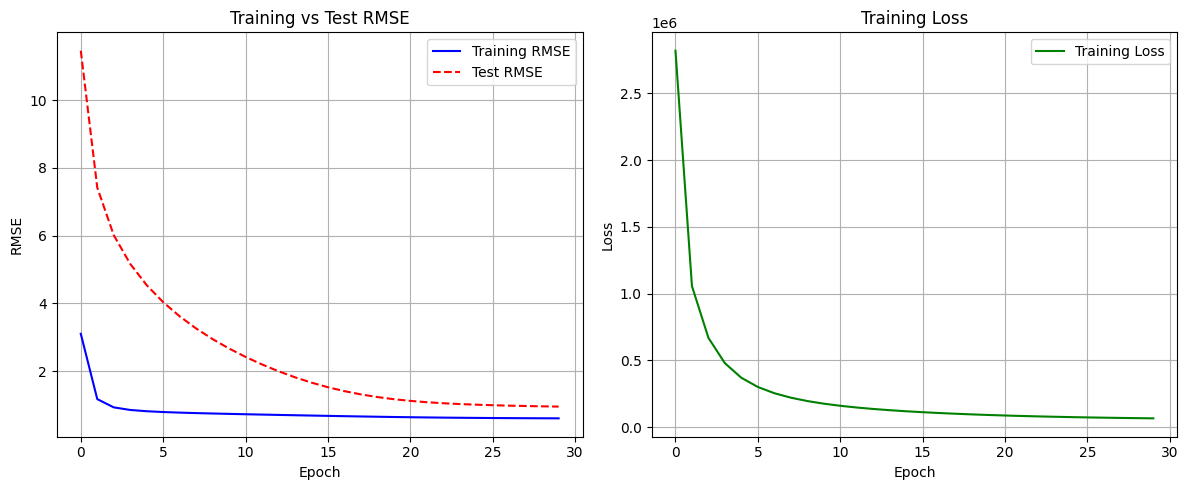

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Training vs Test RMSE
ax1.plot(training_rmse_logs, color='blue', linestyle='-', label='Training RMSE')
ax1.plot(test_rmse_logs, color='red', linestyle='--', label='Test RMSE')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('RMSE')
ax1.set_title('Training vs Test RMSE')
ax1.legend()
ax1.grid(True)

# Plot 2: Training Loss
ax2.plot(training_loss_logs, color='green', linestyle='-', label='Training Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.set_title('Training Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

##Save model in disk

In [30]:
item_counts = np.diff(items_pointers)                      # train ratings per item
sum_r  = np.bincount(train_items, weights=train_ratings, minlength=number_of_items)
sum_r2 = np.bincount(train_items, weights=train_ratings.astype(np.float64) ** 2, minlength=number_of_items)
mean_r = sum_r / np.maximum(item_counts, 1)
item_std = np.sqrt(np.maximum(sum_r2 / np.maximum(item_counts, 1) - mean_r ** 2, 0))

np.savez("item_model.npz",
         items_embeddings=items_embeddings, items_biases=items_biases,
         index_to_item=ratings.index_to_item, item_counts=item_counts, item_std=item_std,
         lamb=lamb, gamma=gamma, tau=tau,
         training_loss_logs=training_loss_logs, training_rmse_logs=training_rmse_logs,
         test_rmse_logs=test_rmse_logs)

np.savez("user_model.npz", users_embeddings=users_embeddings, users_biases=users_biases)   # optional

##Reading data from disk

In [31]:
import numpy as np
import pandas as pd

model = np.load("item_model.npz")
items_embeddings = model["items_embeddings"]
items_biases     = model["items_biases"]
index_to_item    = model["index_to_item"]
item_counts      = model["item_counts"]
item_std         = model["item_std"]

lamb = 0.01
gamma = 0.005

movies = pd.read_csv(path + "/movies.csv")                  # columns: movieId, title, genres
titles = pd.Series(index_to_item).map(dict(zip(movies.movieId, movies.title))).fillna("?").to_numpy()

def find(text):
  hits = np.flatnonzero(pd.Series(titles).str.contains(text, case=False, regex=False).to_numpy())
  for j in hits:
    print(j, titles[j], item_counts[j])
  return hits

##Dummy user test:

In [32]:
def fold_in(item_idx, rates, V, bi, lamb, gamma, n_iter=5):
  k = V.shape[1]
  item_idx = np.asarray(item_idx)
  rates = np.asarray(rates, dtype=np.float64)
  Vu = V[item_idx]
  u = np.zeros(k)
  for _ in range(n_iter):
    # bias, using the current embedding
    resid = rates - Vu @ u - bi[item_idx]
    bu = lamb * resid.sum() / (lamb * len(rates) + gamma)
    # embedding, using the new bias
    y = rates - bi[item_idx] - bu
    u = np.linalg.solve(lamb * (Vu.T @ Vu) + gamma * np.eye(k), lamb * (Vu.T @ y))
  return u, bu

###Score then rank predictions

In [36]:
def recommend(u, w=0.05, min_count=100, exclude=(), top=10):
  score = items_embeddings @ u + w * items_biases           # no user bias, it doesn't change the ranking
  score[item_counts < min_count] = -np.inf                  # drop movies with fewer than min_count training ratings
  score[list(exclude)] = -np.inf
  best = np.argsort(-score)[:top]
  return [(titles[j], round(float(score[j]), 3), int(item_counts[j])) for j in best]

x = find("Fellowship of the Ring")[0]                       # pick the right index from the printout
u, bu = fold_in([x], [5.0], items_embeddings, items_biases, lamb, gamma, n_iter=5)
for row in recommend(u, w=0.05, min_count=500, exclude=[x]):
  print(row)

4888 Lord of the Rings: The Fellowship of the Ring, The (2001) 58427
('Lord of the Rings: The Return of the King, The (2003)', 0.832, 54004)
('Lord of the Rings: The Two Towers, The (2002)', 0.824, 53747)
('Hobbit: An Unexpected Journey, The (2012)', 0.616, 12935)
('Hobbit: The Desolation of Smaug, The (2013)', 0.608, 9697)
('The Hobbit: The Battle of the Five Armies (2014)', 0.59, 6862)
('Hamilton (2020)', 0.485, 1524)
('Thin Red Line, The (1998)', 0.462, 7613)
('Evangelion: 2.0 You Can (Not) Advance (Evangerion shin gekijôban: Ha) (2009)', 0.438, 629)
('Evangelion: 1.0 You Are (Not) Alone (Evangerion shin gekijôban: Jo) (2007)', 0.434, 683)
('Pride and Prejudice (1995)', 0.419, 2463)


[('Drama', 2585), ('Comedy', 2060), ('Thriller', 1365), ('Action', 1287), ('Romance', 966), ('Adventure', 917), ('Crime', 782), ('Sci-Fi', 697), ('Horror', 565), ('Fantasy', 535)]
variance explained by PC1, PC2: [0.066 0.056]


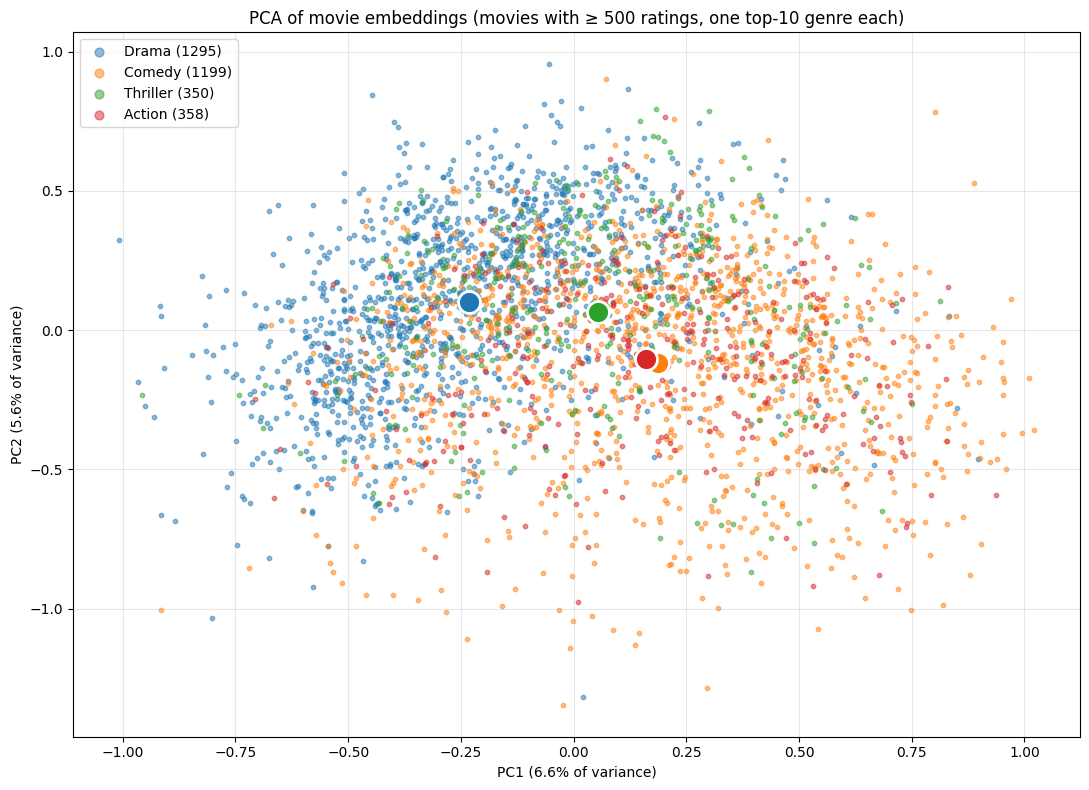

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

min_count = 500                                    # only movies with well-determined vectors
keep = np.flatnonzero(item_counts >= min_count)

# genres per item index (movies.csv has "Action|Adventure|Sci-Fi" style strings)
genres_by_item = pd.Series(index_to_item).map(dict(zip(movies.movieId, movies.genres))).fillna("").to_numpy()
genre_lists = [g.split("|") for g in genres_by_item]

# top 10 genres among the kept movies
ignore = {"(no genres listed)", "IMAX", ""}
counter = Counter(g for j in keep for g in genre_lists[j] if g not in ignore)
top_genres = [g for g, _ in counter.most_common(10)]
print(counter.most_common(10))

# PCA on the item embeddings (fit on all kept movies)
X = items_embeddings[keep]
Xc = X - X.mean(axis=0)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
coords = Xc @ Vt[:2].T
explained = S ** 2 / np.sum(S ** 2)
print("variance explained by PC1, PC2:", explained[:2].round(3))

# keep movies that belong to exactly ONE of the top-10 genres, so each dot has one clear color
label = []
for j in keep:
  hits = [g for g in genre_lists[j] if g in top_genres]
  label.append(hits[0] if len(hits) == 1 else None)
label = np.array(label, dtype=object)
has_label = np.array([l is not None for l in label])

# colors: horror in black, the rest from tab10
palette = plt.cm.tab10.colors
colors, p = {}, 0
for g in top_genres:
  if g == "Horror":
    colors[g] = "black"
  else:
    if palette[p] == plt.cm.tab10.colors[7]:       # skip grey, it looks like "no label"
      p += 1
    colors[g] = palette[p]
    p += 1

fig, ax = plt.subplots(figsize=(11, 8))
for g in top_genres:
  m = has_label & (label == g)
  ax.scatter(coords[m, 0], coords[m, 1], s=10, alpha=0.5, color=colors[g], label=f"{g} ({m.sum()})")
  # centroid of the genre, to see where each group sits
  ax.scatter(coords[m, 0].mean(), coords[m, 1].mean(), s=250, color=colors[g],
             edgecolor="white", linewidth=2, zorder=5)

ax.set_xlabel(f"PC1 ({explained[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.1%} of variance)")
ax.set_title(f"PCA of movie embeddings (movies with ≥ {min_count} ratings, one top-10 genre each)")
ax.legend(markerscale=2, loc="best")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()